<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [qslab](https://github.com/Gokaran-Shukla/qslab) · MIT License — any reuse must keep this copyright notice and credit the author.

# 01 · Getting started: lattices, operators, exact diagonalisation and parallel computing

**What you will learn**
1. Build lattices (chain, square, triangular, honeycomb, kagome) as tori, cylinders and tilted clusters.
2. Write any spin Hamiltonian as a sum of Pauli strings.
3. Run exact diagonalisation (ED) and measure energies, spin, momentum and correlations.
4. Use all cores of a node, several nodes (MPI) or a GPU. All three are optional and controlled by one switch.

Conventions used everywhere in qslab:
* spin-1/2 operators $S^a = \sigma^a/2$;
* a basis state is an integer whose bit $i$ is 0 for $\uparrow$ and 1 for $\downarrow$.

In [1]:
import numpy as np, matplotlib.pyplot as plt, time
import qslab
from qslab import lattice, models, ED, sigma, spin, sdot, exchange
qslab.parallel_info()

{'threads_per_process': 2,
 'numba': True,
 'backend': 'cpu',
 'cupy_gpu': False,
 'mpi': False,
 'mpi_rank': 0,
 'mpi_size': 1,
 'cpu_count': 2,
 'numba_threads': 2}

## 1. Lattices
Every lattice knows its neighbour shells (`bonds(k)`), its plaquettes, its translations and its allowed momenta.
Dashed bonds wrap around the periodic boundary.

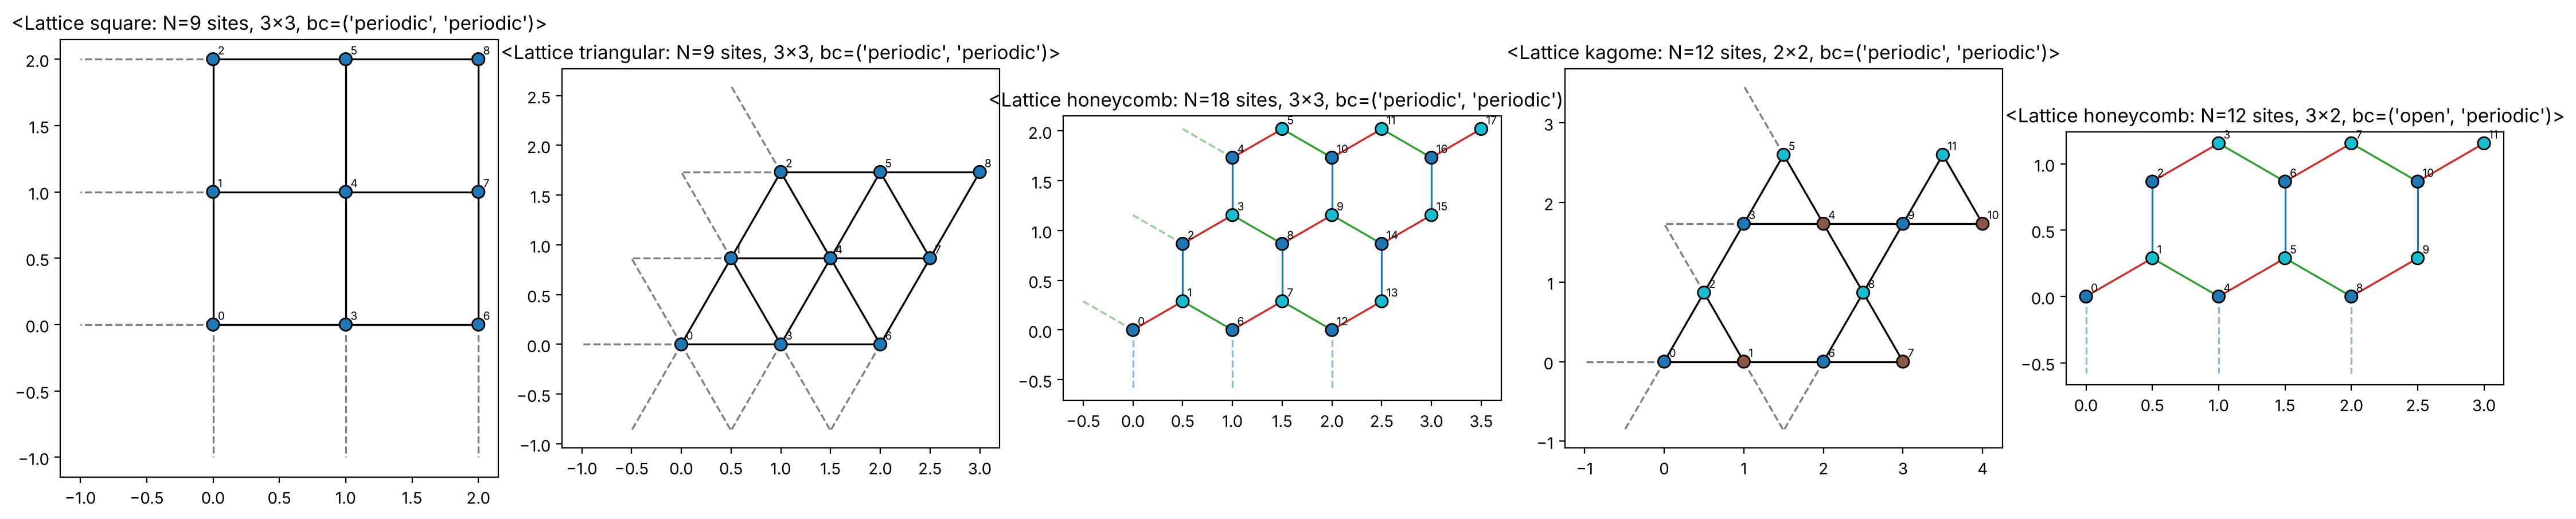

In [2]:
fig, axs = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, lat in zip(axs, [lattice.square(3), lattice.triangular(3), lattice.honeycomb(3),
                         lattice.kagome(2), lattice.honeycomb(3, 2, bc="cylinder")]):
    lat.plot(ax=ax)
plt.tight_layout(); plt.show()

In [3]:
kag = lattice.kagome(2, 2)
print(kag, "| NN bonds:", len(kag.bonds(1)), "| NNN bonds:", len(kag.bonds(2)))
print("plaquettes:", {k: len(kag.plaquettes(k)) for k in ["up", "down", "hexagon"]})
print("allowed momenta (cartesian):\n", np.round(kag.momenta(), 3))

<Lattice kagome: N=12 sites, 2x2, bc=('periodic', 'periodic')> | NN bonds: 24 | NNN bonds: 24
plaquettes: {'up': 4, 'down': 4, 'hexagon': 4}
allowed momenta (cartesian):
 [[ 0.     0.   ]
 [ 0.     1.814]
 [ 1.571 -0.907]
 [ 1.571  0.907]]


Tilted clusters are given by a supercell matrix whose rows are $T_i = M_{i1} a_1 + M_{i2} a_2$.
One example is the $\sqrt{8}\times\sqrt{8}$ square cluster.

In [4]:
tilted = lattice.square(1, supercell=[[2, 2], [-2, 2]])
print(tilted, "coordination", tilted.coordination())

<Lattice square: N=8 sites, supercell=[[2, 2], [-2, 2]]> coordination 4


## 2. Operators: Hamiltonians as Pauli strings
`sigma(i,'x')`, `spin(i,'x')`, `sdot(i,j)` and `exchange(i,j,J)` (with J a scalar, 3-vector or 3×3 matrix) can be added and multiplied freely.

In [5]:
x, y, z = sigma(0, "x"), sigma(0, "y"), sigma(0, "z")
print("sigma^x sigma^y =", x * y)
print("[S_0.S_1, S^z_tot] = 0 ?", sdot(0, 1).conserves_sz())
# A custom Hamiltonian: XXZ ring with a Dzyaloshinskii-Moriya term
N = 8
H = sum((exchange(i, (i + 1) % N, [1, 1, 0.5]) for i in range(N)), qslab.Operator())
D = np.array([[0, 0.2, 0], [-0.2, 0, 0], [0, 0, 0]])   # D_z (S^x S^y - S^y S^x)
H = H + sum((exchange(i, (i + 1) % N, D) for i in range(N)), qslab.Operator())
print(len(H.terms), "Pauli strings; Hermitian:", H.is_hermitian())

sigma^x sigma^y = Operator[(+0+1j) z0]
[S_0.S_1, S^z_tot] = 0 ? True
40 Pauli strings; Hermitian: True


## 3. Exact diagonalisation
`ED` picks the $S^z=0$ sector automatically when $H$ conserves $S^z$. It reports total spin and crystal momentum,
and it gives correlations, structure factors and entanglement.

**Benchmark:** the 4×4 square-lattice antiferromagnet has $E_0 = -11.228483$.

In [6]:
lat = lattice.square(4)
ed = ED(models.heisenberg(lat), lat.N)
t = time.time(); w, v = ed.diagonalize(k=6); print(f"{ed}  ({time.time()-t:.2f}s)")
print("E0 =", w[0], " E0/N =", w[0] / lat.N)
print("total spin of GS:", ed.total_spin(v[:, 0]))
for E, k in ed.momenta(lat)[:4]:
    print(f"  E = {E:.6f}   k.a/2pi = {k}")

<ED N=16 <SpinBasis N=16 n_up=8 (Sz=+0) dim=12870> method=sparse>  (0.09s)
E0 = -11.228483208428854  E0/N = -0.7017802005268033
total spin of GS: 5.551115123125783e-15
  E = -11.228483   k.a/2pi = (np.float64(0.0), np.float64(0.0))
  E = -10.649885   k.a/2pi = (np.float64(0.5), np.float64(0.5))
  E = -9.517688   k.a/2pi = (np.float64(0.0), np.float64(0.0))
  E = -8.886442   k.a/2pi = (np.float64(0.5), np.float64(0.5))


In [7]:
psi = v[:, 0]
C = ed.spin_correlations(psi)
q_Neel = np.array([np.pi, np.pi])
print("S(pi,pi) =", ed.structure_factor(psi, lat.positions, q_Neel, C=C))
print("half-system entanglement entropy:", ed.entanglement_entropy(psi, range(8)))

S(pi,pi) = [4.42443418]
half-system entanglement entropy: 1.8209350816192633


### Bethe-ansatz check (1D)
The Heisenberg chain approaches $E/N = 1/4-\ln 2 = -0.4431$ as $1/L^2$.

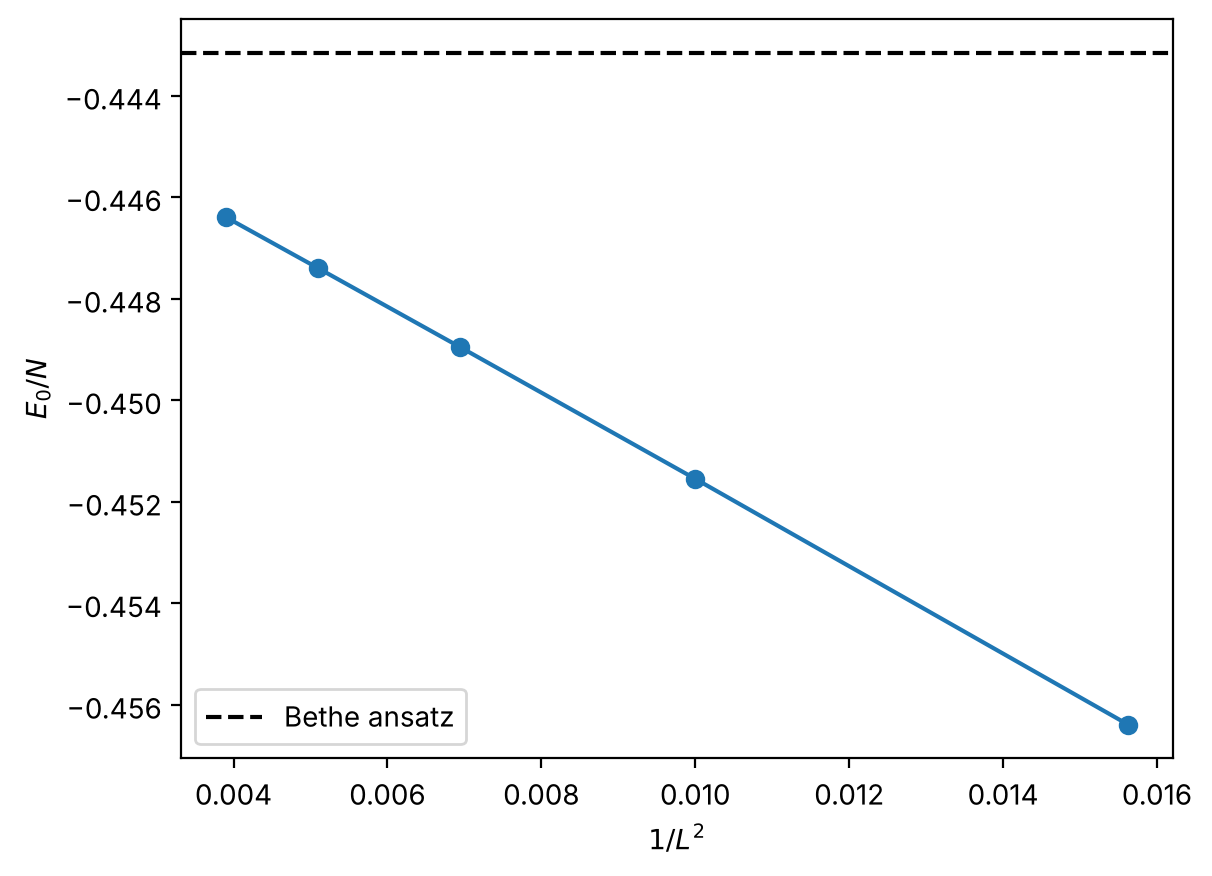

In [8]:
Ls, Es = [8, 10, 12, 14, 16], []
for L in Ls:
    latc, Hc = models.xxz_chain(L)
    Es.append(ED(Hc, L).ground_state()[0] / L)
plt.plot(1 / np.array(Ls) ** 2, Es, "o-")
plt.axhline(models.bethe_energy_per_site(), ls="--", c="k", label="Bethe ansatz")
plt.xlabel("$1/L^2$"); plt.ylabel("$E_0/N$"); plt.legend(); plt.show()

## 4. Parallel computing: one node, many nodes, GPU

| level | how | used by |
|---|---|---|
| **threads (default)** | Numba `prange` kernels + BLAS on all cores | ED matvec (`method='numba'`), DMRG contractions, dense algebra |
| **process pool (default)** | `qslab.pmap(func, items)` | sectors, FTLM vectors, parameter scans, MC temperatures |
| **MPI (optional)** | `mpirun -n 64 python script.py` and `pip install mpi4py` | `pmap` spreads tasks over ranks; VMC/NQS/Majorana-MC chains are reduced with `allreduce` |
| **GPU (optional)** | `qslab.set_backend('gpu')` and `pip install cupy-cuda12x` | ED (cuSPARSE or matrix-free kernel), Lanczos, DMRG, Majorana diagonalisation |

Environment variables: `QSLAB_NUM_THREADS`, `QSLAB_NUM_JOBS`, `QSLAB_BACKEND=gpu`, `QSLAB_USE_MPI`.

In [9]:
qslab.set_num_threads(qslab.get_num_threads())   # e.g. 128 on a full node
lat = lattice.square(4, 5)                        # 20 sites, Sz=0 sector dim 184756
H = models.heisenberg(lat, J2=0.3)
for method in ["sparse", "numba"]:
    t = time.time(); E, _ = ED(H, lat.N, method=method).ground_state(); print(f"{method:7s} E0 = {E:.8f}  ({time.time()-t:.1f}s)")

sparse  E0 = -11.36735260  (3.4s)


numba   E0 = -11.36735260  (19.1s)


`pmap` runs independent jobs in parallel. Here it scans J2 for the 4×4 J1-J2 model.
Under MPI the same line spreads the jobs over every rank of every node.

0.8s


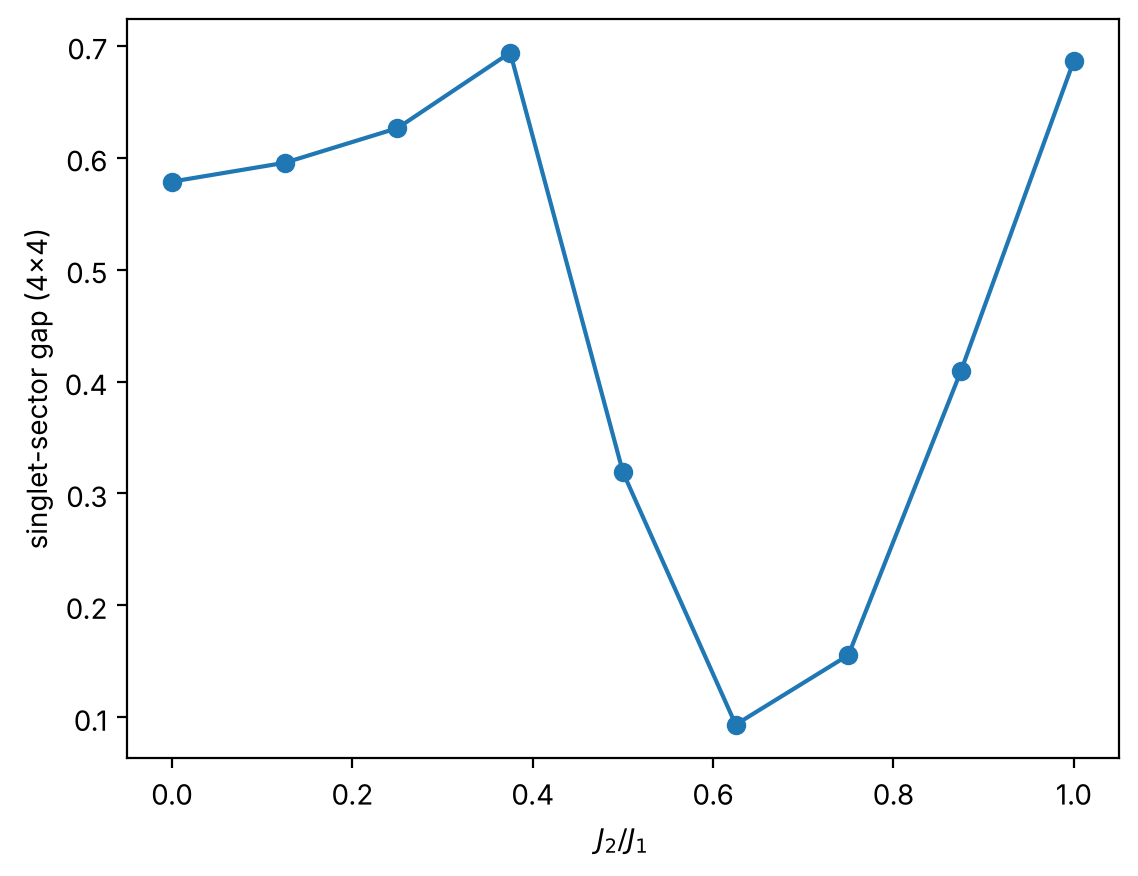

In [10]:
def gap_at(J2):
    lat = lattice.square(4)
    w, _ = ED(models.j1j2_square(lat, J2=J2), 16).diagonalize(k=2)
    return w[1] - w[0]

J2s = np.linspace(0, 1, 9)
t = time.time(); gaps = qslab.pmap(gap_at, J2s); print(f"{time.time()-t:.1f}s")
plt.plot(J2s, gaps, "o-"); plt.xlabel("$J_2/J_1$"); plt.ylabel("singlet-sector gap (4x4)"); plt.show()

### Running on a cluster
Ready-made SLURM scripts are in `examples/`:
* `slurm_single_node.sh`: one node, all cores (threads plus process pool)
* `slurm_multi_node.sh`: `srun` with MPI across nodes (e.g. FTLM, VMC and parameter scans)
* `slurm_gpu.sh`: one GPU, `QSLAB_BACKEND=gpu`

## Quiz
Run `qslab.quiz.run('methods')` for an interactive quiz, or show the questions:

In [11]:
from qslab import quiz
quiz.show("methods")

=== Methods and diagnostics for spin liquids ===
ED, DMRG, partons/VMC, NQS, thermodynamics, parallel computing

Q1. [mcq] Why can't ARPACK reliably count a 4-fold topological degeneracy with a tiny Krylov space?
    (a) Lanczos generates a single vector per degenerate eigenspace from one start vector; restarts or a large Krylov space are needed
    (b) It is complex
    (c) It always can
    (d) Because of round-off

Q2. [mcq] Which quantity distinguishes a gapped Z2 spin liquid from a trivial paramagnet?
    (a) topological entanglement entropy gamma = ln 2
    (b) zero magnetisation
    (c) <S_i.S_j> < 0
    (d) finite gap

Q3. [mcq] A smoking gun for fractionalisation in neutron scattering is
    (a) a spin gap
    (b) a broad continuum in S(q, w) instead of sharp magnons
    (c) a Bragg peak
    (d) a Curie law

Q4. [mcq] The QMC sign problem prevents
    (a) Majorana MC for Kitaev
    (b) unbiased QMC for frustrated Heisenberg models
    (c) ED
    (d) DMRG

Q5. [mcq] In qslab FT